# Bootstrap Sample Size

Find the minimum sample size needed to reach a target margin error, using the bootstrap method.

**Flow:** generate data -> configure the model -> search for the minimum sample size -> inspect the result.


In [1]:
import numpy as np
from bootstrap_sample_size import BootstrapSampleSize
import matplotlib.pyplot as plt

## 1. Demo data

3,000 values from a U-shaped Beta(0.5, 0.5) distribution (both shape parameters below 1). It is far from normal, so a closed-form sample size formula is a poor fit and the bootstrap is a good test.


In [2]:
rng = np.random.default_rng(42)
data = rng.beta(a=0.5, b=0.5, size=3000)

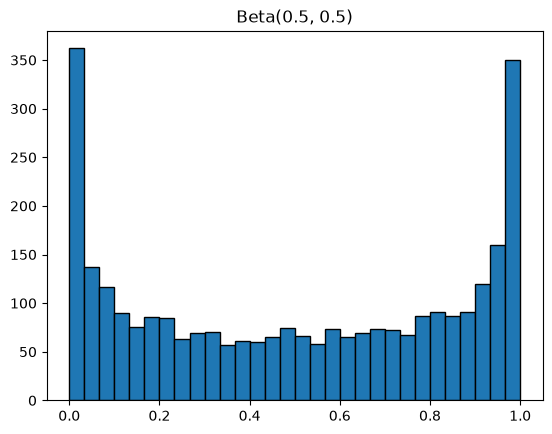

In [3]:
plt.hist(data, bins=30, edgecolor="black")
plt.title("Beta(0.5, 0.5)")
plt.show()

## 2. Configure the model

- `n_bootstrap=2000`: resamples drawn at each sample size
- `n_steps=100`: start at 100 and grow by 100 each iteration
- `metrics=np.mean`: the statistic whose precision we measure
- `margin_error=0.03`: target half-width of the confidence interval
- `confidence=0.95`: 95% interval (2.5% to 97.5% percentiles)
- `seed=42`: reproducible results


In [4]:
model = BootstrapSampleSize(
    data=data,
    n_bootstrap=2000,
    n_steps=100,
    metrics=np.mean,
    margin_error=0.03,
    confidence=0.95,
    seed=42
)

## 3. Find the minimum sample size

The model increases the sample size step by step and stops at the first size whose margin error is below the target. Pass `plot=True` to see the bootstrap distribution at every step.


In [5]:
n_sample = model.find_n_sample()

n-sample minimum found | n-sample : 600


## 4. Conclusion

With this data and `seed=42`, a sample of about **600** observations is enough to estimate the mean within a margin error of 0.03 at 95% confidence.
